# Importancia das variaveis nos cinco modelos de predicao de obito por chikungunya

Este notebook calcula a importancia nativa de cada uma das 29 variaveis preditoras para os cinco algoritmos ja treinados na fase de modelagem: Regressao Logistica, Arvore de Decisao (CART), Random Forest, XGBoost e LightGBM.
Para os quatro modelos baseados em arvore, Arvore de Decisao, Random Forest, XGBoost e LightGBM, a importancia usada e a medida nativa de cada biblioteca: Gini, tambem chamada de MDI, para os dois primeiros, e ganho (gain) para XGBoost e LightGBM.
Para a Regressao Logistica, a importancia agregada por variavel e a soma dos valores absolutos dos coeficientes ajustados, somada entre todas as categorias quando a variavel e categorica e foi codificada em multiplas colunas por one hot encoding.
Nenhum modelo e retreinado neste notebook, os cinco pipelines usados sao exatamente os artefatos finais salvos em `output/modelos/`, ja ajustados em todo o periodo de treino de 2020 a 2023.
O notebook produz uma tabela ranqueada por modelo, uma tabela consolidada com o rank de cada variavel nos cinco modelos e o rank medio entre eles, a concordancia entre os cinco rankings por correlacao de Spearman, e uma tabela detalhada de razao de chances por categoria para a Regressao Logistica.
A comparacao destes resultados com a literatura cientifica sobre fatores de risco de obito por chikungunya nao e feita neste notebook, e fica para uma etapa posterior fora deste notebook.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria os diretorios de saida usados ao longo do notebook.
As tabelas sao salvas em `analysis/results_importancia/`, e os graficos em `analysis/plots/importancia/`.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_importancia"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "importancia"

DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_VARIAVEIS_EM_DESTAQUE = 10

Carrega apenas os preditores do treino completo, ja construidos pelo pipeline de dados, para obter a lista oficial das 29 variaveis originais e separar as numericas das categoricas.
Essa separacao segue exatamente a mesma convencao usada na fase de modelagem, em `utils/preprocessamento.py`, e nenhuma linha do treino e usada para ajustar nada neste notebook, apenas para nomear as colunas.

In [2]:
X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")

COLUNAS_NUMERICAS = preprocessamento.COLUNAS_NUMERICAS
COLUNAS_CATEGORICAS = preprocessamento.obter_colunas_categoricas(X_train)
VARIAVEIS_ORIGINAIS = list(X_train.columns)

len(VARIAVEIS_ORIGINAIS), len(COLUNAS_NUMERICAS), len(COLUNAS_CATEGORICAS)

(29, 3, 26)

Carrega os cinco pipelines finais salvos pela fase de modelagem, cada um ja ajustado em todo o periodo de treino de 2020 a 2023.
Sao usados exclusivamente os artefatos originais, sem o sufixo `_calibrado`, ja que o reescalonador de calibracao e unidimensional e nao contem nenhuma informacao sobre a importancia das 29 variaveis preditoras.

In [3]:
modelos = {algoritmo: joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib") for algoritmo in ALGORITMOS}

{algoritmo: type(modelo.named_steps["classificador"]).__name__ for algoritmo, modelo in modelos.items()}

{'regressao_logistica': 'LogisticRegression',
 'arvore_decisao': 'DecisionTreeClassifier',
 'random_forest': 'RandomForestClassifier',
 'xgboost': 'XGBClassifier',
 'lightgbm': 'LGBMClassifier'}

Define duas funcoes auxiliares usadas pelos tres modelos que dependem do `ColumnTransformer` de codificacao one hot: Regressao Logistica, Arvore de Decisao e Random Forest.
A primeira funcao recupera a variavel original correspondente a uma coluna codificada: uma coluna numerica mantem o proprio nome apos o prefixo `numericas__`, enquanto uma coluna categorica tem o formato `categoricas__{variavel}_{categoria}`, identificado comparando esse sufixo com a lista das 26 variaveis categoricas.
A segunda funcao soma, para cada variavel original, os valores informados em todas as colunas codificadas que pertencem a ela, o que, para a Regressao Logistica, corresponde exatamente a soma dos valores absolutos dos coeficientes das categorias daquela variavel.

In [4]:
def mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador == "numericas":
        return nome_apos_prefixo

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            return variavel_categorica

    raise ValueError(f"Nenhuma variavel original encontrada para {nome_coluna_codificada}")


def agregar_importancia_one_hot_por_variavel(preprocessador, valores_por_coluna_codificada):
    nomes_colunas_codificadas = preprocessador.get_feature_names_out()
    importancia_por_variavel = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)

    for nome_coluna_codificada, valor in zip(nomes_colunas_codificadas, valores_por_coluna_codificada):
        variavel_original = mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
        importancia_por_variavel[variavel_original] += valor

    return importancia_por_variavel

## Regressao Logistica

A Regressao Logistica usa o `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e o valor absoluto do coeficiente ajustado pelo classificador, antes da agregacao pela funcao definida acima.
O sinal original dos coeficientes nao e descartado, e e reaproveitado mais adiante neste notebook na tabela de razao de chances por categoria, ja que a agregacao por soma de valores absolutos remove a direcao do efeito de cada categoria.

In [5]:
preprocessador_regressao_logistica = modelos["regressao_logistica"].named_steps["preprocessador"]
coeficientes_regressao_logistica = modelos["regressao_logistica"].named_steps["classificador"].coef_[0]

importancia_regressao_logistica = agregar_importancia_one_hot_por_variavel(
    preprocessador_regressao_logistica, np.abs(coeficientes_regressao_logistica)
)
importancia_regressao_logistica.sort_values(ascending=False).head(10)

SG_UF         3.479969
CS_ESCOL_N    1.435404
CS_RACA       0.869750
CS_GESTANT    0.865818
VOMITO        0.631020
RENAL         0.560814
IDADE_ANOS    0.560021
HEPATOPAT     0.465303
ARTRITE       0.424554
EXANTEMA      0.404394
dtype: float64

## Arvore de Decisao (CART)

A Arvore de Decisao usa o mesmo tipo de `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e a importancia de Gini, tambem chamada de MDI (mean decrease in impurity), calculada diretamente pelo `DecisionTreeClassifier` ja ajustado.

In [6]:
preprocessador_arvore_decisao = modelos["arvore_decisao"].named_steps["preprocessador"]
mdi_arvore_decisao = modelos["arvore_decisao"].named_steps["classificador"].feature_importances_

importancia_arvore_decisao = agregar_importancia_one_hot_por_variavel(
    preprocessador_arvore_decisao, mdi_arvore_decisao
)
importancia_arvore_decisao.sort_values(ascending=False).head(10)

IDADE_ANOS                   0.547132
TEMPO_SINTOMA_NOTIFICACAO    0.155789
SG_UF                        0.099056
VOMITO                       0.082574
CS_ESCOL_N                   0.026171
DOR_RETRO                    0.024087
SEMANA_EPI_SIN_PRI           0.023512
CS_RACA                      0.012773
CEFALEIA                     0.011176
DOR_COSTAS                   0.009902
dtype: float64

## Random Forest

O Random Forest usa o mesmo tipo de pre-processamento one hot da Arvore de Decisao, e a importancia bruta de cada coluna codificada e a media da importancia de Gini entre todas as arvores do ensemble, tambem calculada diretamente pelo `RandomForestClassifier` ja ajustado.

In [7]:
preprocessador_random_forest = modelos["random_forest"].named_steps["preprocessador"]
mdi_random_forest = modelos["random_forest"].named_steps["classificador"].feature_importances_

importancia_random_forest = agregar_importancia_one_hot_por_variavel(
    preprocessador_random_forest, mdi_random_forest
)
importancia_random_forest.sort_values(ascending=False).head(10)

IDADE_ANOS                   0.167973
SG_UF                        0.106596
TEMPO_SINTOMA_NOTIFICACAO    0.101990
SEMANA_EPI_SIN_PRI           0.074216
CS_ESCOL_N                   0.069860
CS_RACA                      0.043034
HIPERTENSA                   0.038219
VOMITO                       0.034764
EXANTEMA                     0.031506
CS_SEXO                      0.030824
dtype: float64

## XGBoost

O XGBoost usa o imputador categorico nativo de `utils/preprocessamento.py`, que preserva os nomes originais das 29 variaveis sem codificacao one hot, e a importancia nativa usada e o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado.
O booster so reporta ganho para variaveis usadas em pelo menos uma divisao de pelo menos uma arvore, por isso as variaveis sem nenhuma divisao recebem ganho zero antes do ranqueamento, para que as 29 variaveis aparecam completas na tabela final.

In [8]:
booster_xgboost = modelos["xgboost"].named_steps["classificador"].get_booster()
ganho_por_variavel_usada_xgboost = booster_xgboost.get_score(importance_type="gain")

importancia_xgboost = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)
for variavel, ganho in ganho_por_variavel_usada_xgboost.items():
    importancia_xgboost[variavel] = ganho

importancia_xgboost.sort_values(ascending=False).head(10)

IDADE_ANOS                   238.238632
TEMPO_SINTOMA_NOTIFICACAO    123.381615
SG_UF                        119.065948
VOMITO                       118.526337
CS_ESCOL_N                   103.372841
CS_SEXO                       94.158020
ARTRITE                       89.252190
CS_GESTANT                    81.002892
NAUSEA                        80.878815
CS_RACA                       78.399597
dtype: float64

## LightGBM

O LightGBM usa o mesmo imputador categorico nativo do XGBoost, e a importancia nativa usada e tambem o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado, que ja retorna um valor, possivelmente zero, para cada uma das 29 variaveis.

In [9]:
booster_lightgbm = modelos["lightgbm"].named_steps["classificador"].booster_

importancia_lightgbm = pd.Series(
    booster_lightgbm.feature_importance(importance_type="gain"),
    index=booster_lightgbm.feature_name(),
).reindex(VARIAVEIS_ORIGINAIS)

importancia_lightgbm.sort_values(ascending=False).head(10)

IDADE_ANOS                   32911.202135
SG_UF                        15402.786852
TEMPO_SINTOMA_NOTIFICACAO     9017.838266
CS_ESCOL_N                    5203.255501
SEMANA_EPI_SIN_PRI            3497.441208
VOMITO                        2540.461885
EXANTEMA                      2441.658098
CS_RACA                       2054.867596
ARTRITE                       1394.253498
CS_GESTANT                    1196.192997
dtype: float64

## Tabela consolidada de importancia bruta

Reune as cinco series de importancia num unico dicionario, na mesma ordem dos cinco algoritmos usada pelo restante do notebook, e organiza o resultado numa unica tabela com as 29 variaveis nas linhas e os cinco algoritmos nas colunas.
Essa tabela bruta e a base tanto das tabelas individuais ranqueadas por modelo quanto da tabela consolidada entre modelos e da matriz de concordancia de Spearman, mais adiante, e e salva em `analysis/results_importancia/importancia_bruta_por_modelo.csv`.

In [10]:
IMPORTANCIA_POR_ALGORITMO = {
    "regressao_logistica": importancia_regressao_logistica,
    "arvore_decisao": importancia_arvore_decisao,
    "random_forest": importancia_random_forest,
    "xgboost": importancia_xgboost,
    "lightgbm": importancia_lightgbm,
}

tabela_importancia_bruta = pd.DataFrame(IMPORTANCIA_POR_ALGORITMO).loc[VARIAVEIS_ORIGINAIS]

tabela_importancia_bruta.rename_axis("variavel").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "importancia_bruta_por_modelo.csv", index=False
)
tabela_importancia_bruta

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
CS_SEXO,0.143155,0.007827,0.030824,94.158020,1003.132906
CS_GESTANT,0.865818,0.000000,0.029824,81.002892,1196.192997
CS_RACA,0.869750,0.012773,0.043034,78.399597,2054.867596
CS_ESCOL_N,1.435404,0.026171,0.069860,103.372841,5203.255501
SG_UF,3.479969,0.099056,0.106596,119.065948,15402.786852
FEBRE,0.135654,0.000000,0.015645,0.000000,97.631758
MIALGIA,0.041550,0.000000,0.023229,54.782990,65.264099
CEFALEIA,0.276835,0.011176,0.028711,52.105133,492.319300
EXANTEMA,0.404394,0.000000,0.031506,76.971184,2441.658098
VOMITO,0.631020,0.082574,0.034764,118.526337,2540.461885


Para cada algoritmo, ordena as 29 variaveis pela importancia em ordem decrescente, atribui um rank de 1 a 29, e marca como `destaque_top10` as 10 variaveis de maior importancia daquele modelo.
Cada tabela individual e salva separadamente em `analysis/results_importancia/importancia_{algoritmo}.csv`, com a variavel, a importancia bruta, o rank e a marcacao de top 10.

In [11]:
tabelas_ranqueadas_por_algoritmo = {}
for algoritmo in ALGORITMOS:
    tabela_ranqueada = (
        tabela_importancia_bruta[algoritmo].rename("importancia").rename_axis("variavel").reset_index()
    )
    tabela_ranqueada = tabela_ranqueada.sort_values("importancia", ascending=False).reset_index(drop=True)
    tabela_ranqueada["rank"] = tabela_ranqueada.index + 1
    tabela_ranqueada["destaque_top10"] = tabela_ranqueada["rank"] <= NUMERO_VARIAVEIS_EM_DESTAQUE

    tabela_ranqueada.to_csv(DIRETORIO_RESULTADOS_ANALISE / f"importancia_{algoritmo}.csv", index=False)
    tabelas_ranqueadas_por_algoritmo[algoritmo] = tabela_ranqueada

tabelas_ranqueadas_por_algoritmo["random_forest"].head(10)

,variavel,importancia,rank,destaque_top10
0,IDADE_ANOS,0.167973,1,True
1,SG_UF,0.106596,2,True
2,TEMPO_SINTOMA_NOTIFICACAO,0.101990,3,True
3,SEMANA_EPI_SIN_PRI,0.074216,4,True
4,CS_ESCOL_N,0.069860,5,True
5,CS_RACA,0.043034,6,True
6,HIPERTENSA,0.038219,7,True
7,VOMITO,0.034764,8,True
8,EXANTEMA,0.031506,9,True
9,CS_SEXO,0.030824,10,True


Gera, num painel com um grafico de barras horizontais por algoritmo, as 10 variaveis de maior importancia de cada um dos cinco modelos, da menos para a mais importante de baixo para cima.
Cada painel usa a propria escala do eixo de importancia, ja que a unidade de medida difere entre os modelos: valor absoluto de coeficiente para a Regressao Logistica, importancia de Gini para Arvore de Decisao e Random Forest, e ganho para XGBoost e LightGBM.
O grafico e salvo em `analysis/plots/importancia/top10_variaveis_por_modelo.png`.

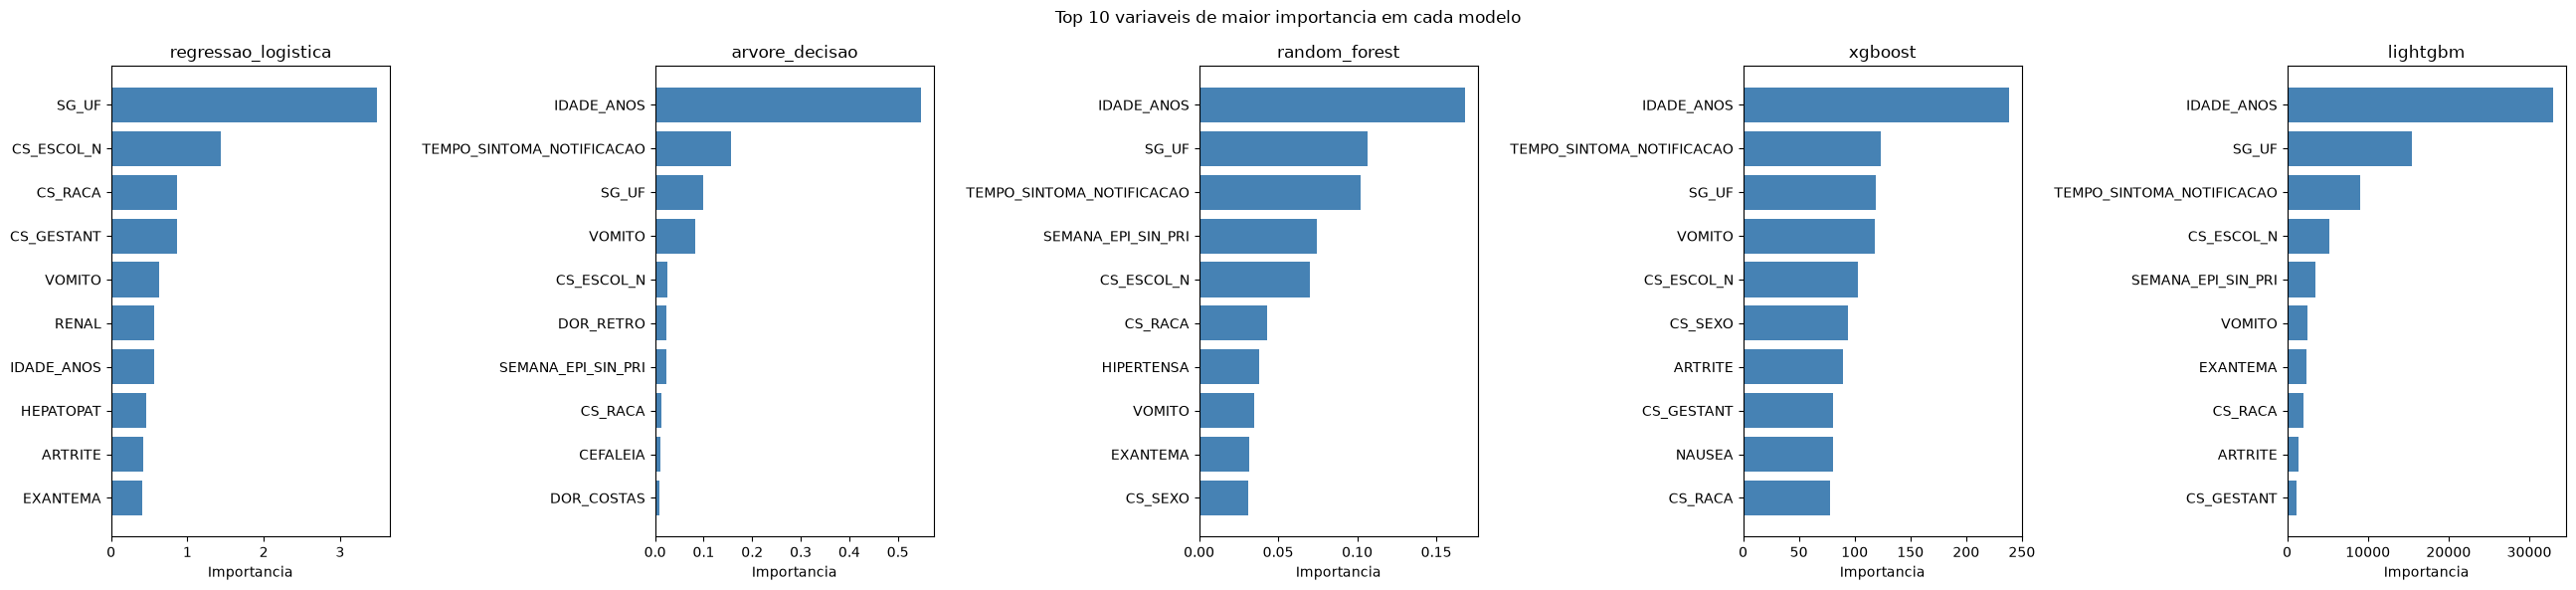

In [12]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(26, 6))

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    top10_algoritmo = tabelas_ranqueadas_por_algoritmo[algoritmo].head(NUMERO_VARIAVEIS_EM_DESTAQUE).iloc[::-1]
    eixo_atual.barh(top10_algoritmo["variavel"], top10_algoritmo["importancia"], color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Importancia")

figura.suptitle("Top 10 variaveis de maior importancia em cada modelo")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "top10_variaveis_por_modelo.png", dpi=150)
plt.show()

## Tabela consolidada entre os cinco modelos

Converte a importancia bruta de cada algoritmo em rank, de 1, a mais importante, a 29, a menos importante, usando rank medio para desempatar variaveis de importancia exatamente igual, o que ocorre com frequencia na Arvore de Decisao, no XGBoost e no LightGBM, cujas importancias nativas sao exatamente zero para as variaveis nunca usadas em nenhuma divisao.
Calcula o rank medio entre os cinco modelos para cada variavel, e ordena a tabela final por esse rank medio, da variavel mais importante em media a menos importante em media.
A tabela e salva em `analysis/results_importancia/ranking_consolidado_5_modelos.csv`.

In [13]:
tabela_rank_por_algoritmo = tabela_importancia_bruta.rank(ascending=False, method="average")
tabela_rank_por_algoritmo = tabela_rank_por_algoritmo.rename(
    columns={algoritmo: f"rank_{algoritmo}" for algoritmo in ALGORITMOS}
)
tabela_rank_por_algoritmo["rank_medio"] = tabela_rank_por_algoritmo.mean(axis=1)

tabela_rank_consolidada = (
    tabela_rank_por_algoritmo.rename_axis("variavel")
    .reset_index()
    .sort_values("rank_medio")
    .reset_index(drop=True)
)
tabela_rank_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "ranking_consolidado_5_modelos.csv", index=False
)
tabela_rank_consolidada

,variavel,rank_regressao_logistica,rank_arvore_decisao,rank_random_forest,rank_xgboost,rank_lightgbm,rank_medio
0,SG_UF,1.0,3.0,2.0,3.0,2.0,2.2
1,IDADE_ANOS,7.0,1.0,1.0,1.0,1.0,2.2
2,CS_ESCOL_N,2.0,5.0,5.0,5.0,4.0,4.2
3,VOMITO,5.0,4.0,8.0,4.0,6.0,5.4
4,TEMPO_SINTOMA_NOTIFICACAO,17.0,2.0,3.0,2.0,3.0,5.4
5,CS_RACA,3.0,8.0,6.0,10.0,8.0,7.0
6,CS_GESTANT,4.0,20.5,11.0,8.0,10.0,10.7
7,SEMANA_EPI_SIN_PRI,27.0,7.0,4.0,14.0,5.0,11.4
8,EXANTEMA,10.0,20.5,9.0,11.0,7.0,11.5
9,CS_SEXO,21.0,11.0,10.0,6.0,13.0,12.2


## Concordancia entre os rankings dos cinco modelos

Calcula a correlacao de Spearman entre as cinco colunas de importancia bruta, o que equivale a correlacionar os rankings das 29 variaveis entre cada par de modelos, numa matriz 5 por 5.
Uma correlacao proxima de 1 indica que dois modelos ordenam as 29 variaveis de forma quase identica, enquanto uma correlacao proxima de 0 indica rankings praticamente independentes entre si.
A matriz e salva em `analysis/results_importancia/concordancia_spearman_entre_modelos.csv`.

In [14]:
matriz_spearman = tabela_importancia_bruta.corr(method="spearman")

matriz_spearman.rename_axis("algoritmo").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "concordancia_spearman_entre_modelos.csv", index=False
)
matriz_spearman

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
regressao_logistica,1.000000,0.383060,0.458621,0.620055,0.664694
arvore_decisao,0.383060,1.000000,0.721520,0.631039,0.758671
random_forest,0.458621,0.721520,1.000000,0.778789,0.824992
xgboost,0.620055,0.631039,0.778789,1.000000,0.901734
lightgbm,0.664694,0.758671,0.824992,0.901734,1.000000


Gera um heatmap da matriz de concordancia de Spearman entre os cinco modelos, com o valor de cada par anotado diretamente sobre a celula correspondente.
O grafico e salvo em `analysis/plots/importancia/heatmap_concordancia_spearman.png`.

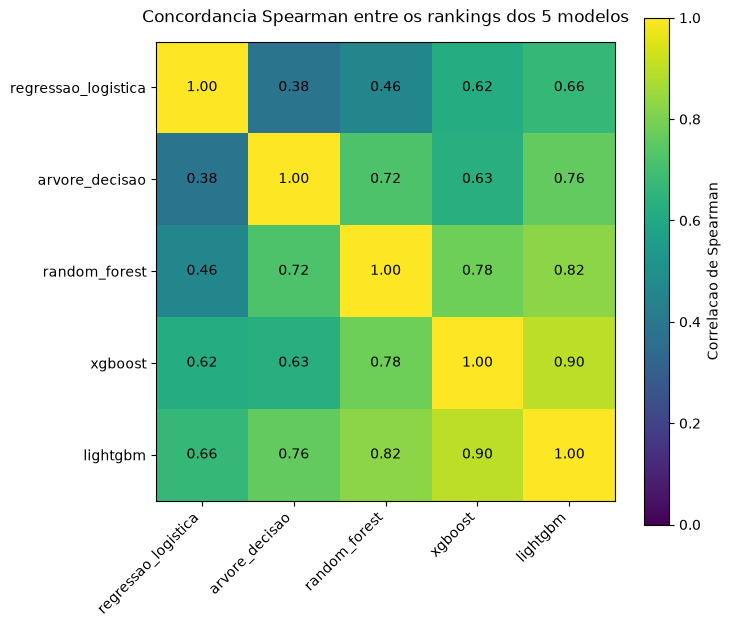

In [15]:
figura, eixo = plt.subplots(figsize=(7.5, 6.5))
mapa_cores = eixo.imshow(matriz_spearman, cmap="viridis", vmin=0, vmax=1)

eixo.set_xticks(range(len(ALGORITMOS)))
eixo.set_xticklabels(ALGORITMOS, rotation=45, ha="right")
eixo.set_yticks(range(len(ALGORITMOS)))
eixo.set_yticklabels(ALGORITMOS)

for linha in range(len(ALGORITMOS)):
    for coluna in range(len(ALGORITMOS)):
        eixo.text(
            coluna, linha, f"{matriz_spearman.iloc[linha, coluna]:.2f}", ha="center", va="center", color="black"
        )

eixo.set_title("Concordancia Spearman entre os rankings dos 5 modelos", pad=14)
figura.colorbar(mapa_cores, ax=eixo, label="Correlacao de Spearman")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "heatmap_concordancia_spearman.png", dpi=150)
plt.show()

## Razao de chances por categoria na Regressao Logistica

A importancia agregada por variavel, usada nas secoes anteriores, soma os valores absolutos dos coeficientes de todas as categorias de uma mesma variavel, o que e adequado para comparar a Regressao Logistica aos demais modelos, mas descarta tanto o sinal quanto a magnitude isolada de cada categoria.
Esta secao recupera, para cada uma das 26 variaveis categoricas, o coeficiente e a razao de chances, `exp(coeficiente)`, de cada categoria individualmente, o nivel de detalhe clinicamente mais interpretavel para esse modelo.
Uma razao de chances acima de 1 indica que a categoria, isolada, esta associada a uma chance maior de obito em relacao ao restante do modelo ajustado, e uma razao de chances abaixo de 1 indica o efeito inverso.
A tabela e salva em `analysis/results_importancia/razao_de_chances_por_categoria_regressao_logistica.csv`.

In [16]:
nomes_colunas_codificadas_regressao_logistica = preprocessador_regressao_logistica.get_feature_names_out()

linhas_razao_de_chances = []
for nome_coluna_codificada, coeficiente in zip(
    nomes_colunas_codificadas_regressao_logistica, coeficientes_regressao_logistica
):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador != "categoricas":
        continue

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            categoria = nome_apos_prefixo[len(variavel_categorica) + 1 :]
            linhas_razao_de_chances.append(
                {
                    "variavel": variavel_categorica,
                    "categoria": categoria,
                    "coeficiente": coeficiente,
                    "razao_de_chances": np.exp(coeficiente),
                }
            )
            break

tabela_razao_de_chances_categorica = pd.DataFrame(linhas_razao_de_chances)
tabela_razao_de_chances_categorica["categoria"] = tabela_razao_de_chances_categorica["categoria"].apply(
    lambda valor: "ausente_sem_imputacao" if valor is None or valor == "None" else valor
)
tabela_razao_de_chances_categorica = tabela_razao_de_chances_categorica.sort_values(
    "razao_de_chances", ascending=False
).reset_index(drop=True)

tabela_razao_de_chances_categorica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "razao_de_chances_por_categoria_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_categorica.head(10)

,variavel,categoria,coeficiente,razao_de_chances
0,SG_UF,25,0.683587,1.980971
1,SG_UF,52,0.456965,1.579273
2,VOMITO,1,0.312003,1.366159
3,RENAL,1,0.276900,1.319035
4,SG_UF,31,0.255202,1.290723
5,CS_RACA,4,0.247744,1.281132
6,CS_ESCOL_N,4,0.230151,1.258790
7,HEPATOPAT,1,0.229145,1.257524
8,CS_ESCOL_N,6,0.218346,1.244017
9,ARTRITE,2,0.208771,1.232162


A categoria `ausente_sem_imputacao` de `CS_ESCOL_N`, visivel na tabela quando a variavel aparece, corresponde a 907 dos 7171 casos de treino cujo nivel de escolaridade nao foi informado.
Esses casos nao foram convertidos para a categoria constante `ausente`, usada para todas as demais variaveis categoricas, porque o valor ausente nessa coluna especifica e representado no dado tratado pelo objeto `None`, que o `SimpleImputer` de `scikit-learn` nao reconhece como ausente numa coluna de tipo texto.
Essa e uma particularidade pontual deste pipeline ja treinado, e afeta apenas o rotulo dessa categoria especifica na tabela de razao de chances, sem nenhum efeito sobre a importancia agregada de `CS_ESCOL_N` nas secoes anteriores, nem sobre nenhuma outra das 29 variaveis.

In [17]:
numero_casos_categoria_ausente_sem_imputacao = int(X_train["CS_ESCOL_N"].isna().sum())
numero_casos_categoria_ausente_sem_imputacao, len(X_train)

(907, 7171)

Como os tres preditores numericos, `IDADE_ANOS`, `SEMANA_EPI_SIN_PRI` e `TEMPO_SINTOMA_NOTIFICACAO`, foram padronizados antes do ajuste da Regressao Logistica, cada um tem um unico coeficiente, e a razao de chances correspondente e por aumento de um desvio padrao, nao por uma unidade bruta da variavel, como um ano de idade.
Esta tabela complementar reune o coeficiente e a razao de chances por desvio padrao desses tres preditores, e e salva em `analysis/results_importancia/coeficientes_variaveis_numericas_regressao_logistica.csv`.

In [18]:
linhas_razao_de_chances_numericas = []
for variavel_numerica in COLUNAS_NUMERICAS:
    indice_coluna = list(nomes_colunas_codificadas_regressao_logistica).index(f"numericas__{variavel_numerica}")
    coeficiente = coeficientes_regressao_logistica[indice_coluna]
    linhas_razao_de_chances_numericas.append(
        {
            "variavel": variavel_numerica,
            "coeficiente_por_desvio_padrao": coeficiente,
            "razao_de_chances_por_desvio_padrao": np.exp(coeficiente),
        }
    )

tabela_razao_de_chances_numerica = (
    pd.DataFrame(linhas_razao_de_chances_numericas)
    .sort_values("razao_de_chances_por_desvio_padrao", ascending=False)
    .reset_index(drop=True)
)

tabela_razao_de_chances_numerica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "coeficientes_variaveis_numericas_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_numerica

,variavel,coeficiente_por_desvio_padrao,razao_de_chances_por_desvio_padrao
0,IDADE_ANOS,0.560021,1.750709
1,TEMPO_SINTOMA_NOTIFICACAO,0.221720,1.248222
2,SEMANA_EPI_SIN_PRI,0.042744,1.043671


## Sintese dos achados

Idade (`IDADE_ANOS`) e a unidade federada de residencia (`SG_UF`) sao as duas variaveis de maior importancia media entre os cinco modelos, com rank medio de 2,2 em ambos os casos, seguidas por escolaridade (`CS_ESCOL_N`), com rank medio de 4,2, e por vomito (`VOMITO`) e tempo entre inicio dos sintomas e notificacao (`TEMPO_SINTOMA_NOTIFICACAO`), ambas com rank medio de 5,4.
Idade e a variavel de maior importancia isolada em quatro dos cinco modelos, Arvore de Decisao, Random Forest, XGBoost e LightGBM, e e a unica variavel presente no top 5 dos cinco modelos ao mesmo tempo.
A Regressao Logistica e a unica excecao a esse padrao: idade aparece apenas na setima posicao desse modelo, atras de `SG_UF`, `CS_ESCOL_N`, `CS_RACA`, `CS_GESTANT` e `VOMITO`, nessa ordem.

Essa posicao baixa de idade na Regressao Logistica nao indica necessariamente um efeito clinico menor, e sim uma consequencia direta do metodo de agregacao usado para esse modelo, pedido explicitamente neste estudo: a importancia de uma variavel categorica e a soma dos valores absolutos dos coeficientes de todas as suas categorias, o que favorece mecanicamente variaveis de alta cardinalidade.
`SG_UF` tem 27 categorias distintas e `CS_ESCOL_N` tem 12, enquanto idade, por ser numerica, contribui com um unico coeficiente para essa soma, e por isso as duas variaveis categoricas de maior cardinalidade dominam o topo do ranking da Regressao Logistica mesmo quando o efeito de cada categoria individual, isolada, e moderado.
Essa ressalva sobre cardinalidade deve ser levada em conta em qualquer leitura comparativa entre a Regressao Logistica e os demais modelos para as variaveis categoricas de muitas categorias, em particular `SG_UF` e `CS_ESCOL_N`.

A semana epidemiologica de inicio dos sintomas (`SEMANA_EPI_SIN_PRI`) e outro caso notavel de discordancia entre os cinco modelos: ocupa a quarta posicao no Random Forest e a quinta no LightGBM, mas apenas a vigesima setima posicao na Regressao Logistica.
Como essa variavel e numerica e entra na Regressao Logistica sem nenhuma transformacao nao linear, essa discordancia sugere que a relacao entre semana epidemiologica e risco de obito, se existir, nao e bem aproximada por um unico termo linear, algo que os quatro modelos baseados em arvore conseguem capturar por meio de multiplas divisoes ao longo da variavel.

A Arvore de Decisao atribui importancia exatamente igual a zero a 18 das 29 variaveis, pois a arvore final selecionada pela busca de hiperparametros tem poucas divisoes, o que faz essas 18 variaveis compartilharem o mesmo rank, 20,5, na tabela consolidada.
O Random Forest, por ser um ensemble de muitas arvores, nao tem nenhuma variavel com importancia exatamente zero, o que torna seu ranking mais informativo do que o da Arvore de Decisao isolada justamente nas variaveis de importancia mais baixa.
XGBoost e LightGBM tambem tem variaveis de ganho exatamente zero, 7 e 6 respectivamente, e essas variaveis estao sempre entre as de importancia mais baixa nos demais modelos, como `LACO`, `HEMATOLOG`, `ACIDO_PEPT`, `AUTO_IMUNE` e `PETEQUIA_N`.

A correlacao de Spearman entre os rankings dos cinco modelos varia de 0,383, entre Regressao Logistica e Arvore de Decisao, a 0,902, entre XGBoost e LightGBM, com media de 0,674 entre os dez pares possiveis de modelos.
Os quatro modelos baseados em arvore concordam fortemente entre si, com correlacoes de Spearman entre 0,631 e 0,902, o que e esperado por todos usarem a mesma familia de medida de importancia baseada em divisoes de arvore.
A Regressao Logistica e o modelo menos alinhado aos demais, com correlacoes de Spearman entre 0,383 e 0,665, consistente com a ressalva sobre cardinalidade descrita acima e com o fato de ser o unico modelo linear entre os cinco.

Na tabela de razao de chances por categoria da Regressao Logistica, as duas categorias de maior razao de chances sao ambas de `SG_UF`, as unidades federadas de codigo 25 e 52, com razao de chances de 1,98 e 1,58, seguidas pela categoria 1 de `VOMITO`, com razao de chances de 1,37.
A categoria de menor razao de chances e a categoria 9 de `CS_RACA`, com razao de chances de 0,65, seguida pela categoria 2 de `VOMITO`, com razao de chances de 0,73.
Os tres preditores numericos tem razao de chances por desvio padrao de 1,75 para idade, 1,25 para o tempo entre inicio dos sintomas e notificacao, e 1,04 para a semana epidemiologica, sempre por um aumento de um desvio padrao, e nao por uma unidade bruta da variavel, ja que as tres foram padronizadas antes do ajuste da Regressao Logistica.
Os codigos de categoria de `SG_UF`, `CS_RACA` e das demais variaveis categoricas seguem a codificacao numerica original do SINAN, e nao sao decodificados neste notebook.

Este notebook se limita a produzir e descrever estes resultados quantitativos internos ao estudo, sem comparacao com a literatura cientifica sobre fatores de risco de obito por chikungunya, etapa que fica para um momento posterior fora deste notebook.